# U-Net — Training Methodology

## 1. Weighted Cross-Entropy and Weight Map

Implementation and visualization of the pixel-wise
weighting strategy proposed by Ronneberger et al. (2015).

In [1]:
import sys
from pathlib import Path

import torch
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT))

from src.unet import UNet
from src.loss import WeightedCrossEntropyLoss
from src.weight_map import compute_weight_map

torch.manual_seed(42)

device = torch.device(
    "mps" if torch.backends.mps.is_available()
    else "cpu"
)

print("Device:", device)

Device: mps


In [2]:
size = 256

y, x = np.ogrid[:size, :size]

instance_mask = np.zeros(
    (size, size),
    dtype=np.int32
)

# Cell 1
instance_mask[
    (x - 80)**2 + (y - 100)**2 < 35**2
] = 1

# Cell 2
instance_mask[
    (x - 155)**2 + (y - 100)**2 < 35**2
] = 2

# Cell 3
instance_mask[
    (x - 118)**2 + (y - 175)**2 < 35**2
] = 3

binary_mask = (instance_mask > 0).astype(np.int64)

weight_map = compute_weight_map(
    instance_mask,
    w0=10,
    sigma=5
)

In [3]:
size = 256

y, x = np.ogrid[:size, :size]

instance_mask = np.zeros(
    (size, size),
    dtype=np.int32
)

# Cell 1
instance_mask[
    (x - 80)**2 + (y - 100)**2 < 35**2
] = 1

# Cell 2
instance_mask[
    (x - 155)**2 + (y - 100)**2 < 35**2
] = 2

# Cell 3
instance_mask[
    (x - 118)**2 + (y - 175)**2 < 35**2
] = 3

binary_mask = (instance_mask > 0).astype(np.int64)

weight_map = compute_weight_map(
    instance_mask,
    w0=10,
    sigma=5
)

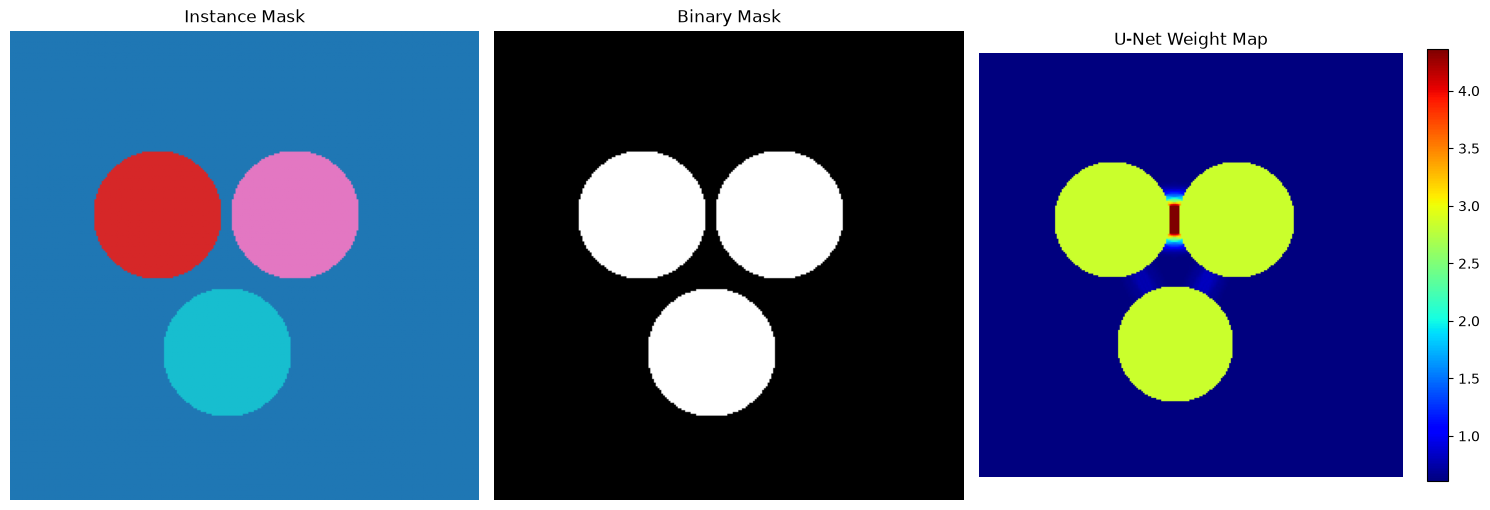

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(instance_mask, cmap="tab10")
axes[0].set_title("Instance Mask")

axes[1].imshow(binary_mask, cmap="gray")
axes[1].set_title("Binary Mask")

im = axes[2].imshow(weight_map, cmap="jet")
axes[2].set_title("U-Net Weight Map")

fig.colorbar(im, ax=axes[2], fraction=0.046)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [5]:
fig.savefig(
    ROOT / "results" / "weight_map_visualization.png",
    dpi=200,
    bbox_inches="tight"
)

print("Weight map saved successfully.")

Weight map saved successfully.
